# Probability calibration — Kaggle Credit Card Fraud (Phase 7)

A narrative walk-through of the Phase 7 results. All logic lives in `src/` (`src/models/calibrate.py`, `src/models/calibration_report.py`); this notebook only calls it and explains what comes out.

**Setup.** Time-ordered 60 / 20 / 20 split. Models are trained on the first 60% (train), every choice (calibrator parameters, Platt vs isotonic, thresholds) is made on the next 20% (validation), and the last 20% (test) is used only to report. The test slice is identical to the old 80 / 20 split's, so old and new test numbers are comparable.

Three XGBoost variants, same hyperparameters:
- **unweighted**: no imbalance handling (the calibration control)
- **class_weighted**: `scale_pos_weight = n_neg / n_pos` on the train slice
- **smote**: trained on SMOTE-resampled, 50/50 data

In [1]:
import sys
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd()
    for parent in [path, *path.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"Could not locate project root (missing {marker})")


project_root = find_project_root()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import joblib
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import Image, display

from src.config import (
    CALIBRATION_BIN_EDGES,
    COST_FALSE_NEGATIVE,
    COST_FALSE_POSITIVE,
    MODEL_ARTIFACT_CLASS_WEIGHTED_FILE,
    REPORTS_DIR,
)
from src.data.load import scan_raw_data
from src.data.preprocess import clean, time_aware_train_val_test_split
from src.models.calibrate import analytic_threshold, model_log_odds
from src.models.calibration_report import compute_report
from src.models.evaluate import plot_reliability_diagram

pd.set_option("display.float_format", lambda x: f"{x:.4g}")

# Fits Platt and isotonic per model on validation, scores all 9 combinations on test.
report = compute_report()
report["n_fraud"]

{'train': 342, 'val': 57, 'test': 74}

Only **57 frauds in validation** and **74 in test**. Every calibration and threshold estimate below rests on a few dozen positives, which is the single most important caveat in this notebook. Note also that the fraud rate moves between windows: 0.20% in train, 0.10% in validation, 0.13% in test.

## 1. Ranking vs level: why calibration is separate from PR-AUC

PR-AUC only asks whether frauds are scored *above* legitimate transactions. It is unchanged by any strictly increasing transform of the scores. Calibration asks something else: when the model says 5%, do about 5% of those transactions turn out to be fraud? A model can rank perfectly and still be badly miscalibrated.

Platt scaling is exactly such a strictly increasing transform, `logit(p_cal) = a · score + b` with `a > 0`, so it can fix the level without touching the ranking:

In [2]:
metrics = pd.DataFrame(report["metrics_on_test"])
metrics[metrics["calibration"].isin(["raw", "platt"])][
    ["model", "calibration", "pr_auc", "brier", "log_loss", "o_to_e", "slope"]
]

,model,calibration,pr_auc,brier,log_loss,o_to_e,slope
0,unweighted,raw,0.7958,0.0004178,0.003006,1.453,0.856
1,unweighted,platt,0.7958,0.0003997,0.002552,1.118,0.9924
3,class_weighted,raw,0.7769,0.000469,0.00303,1.036,0.7049
4,class_weighted,platt,0.7769,0.0004341,0.002757,1.121,0.9919
6,smote,raw,0.7922,0.0004548,0.002929,0.7224,0.8094
7,smote,platt,0.7922,0.0003743,0.002575,1.065,0.9992


In [3]:
# Same point on real transactions: the ten highest-risk test transactions,
# raw class-weighted score vs its Platt-calibrated probability.
_, _, test_df = pl.collect_all(time_aware_train_val_test_split(clean(scan_raw_data())))
test_df = test_df.to_pandas()
X_test, y_test = test_df.drop(columns=["Class"]), test_df["Class"]

model = joblib.load(MODEL_ARTIFACT_CLASS_WEIGHTED_FILE)
platt = report["calibrators"]["class_weighted"]["platt"]
raw = model.predict_proba(X_test)[:, 1]
calibrated = platt.predict_proba(model, X_test)

top = np.argsort(-raw)[:10]
print("same ordering:", np.array_equal(np.argsort(-raw, kind="stable"), np.argsort(-calibrated, kind="stable")))
pd.DataFrame({"raw score": raw[top], "calibrated probability": calibrated[top], "is fraud": y_test.to_numpy()[top]})

same ordering: True


,raw score,calibrated probability,is fraud
0,0.9999,0.992,1
1,0.9999,0.9917,1
2,0.9999,0.9912,1
3,0.9999,0.9912,1
4,0.9999,0.9909,1
5,0.9999,0.9902,1
6,0.9998,0.9896,1
7,0.9998,0.9891,1
8,0.9998,0.9888,1
9,0.9998,0.9882,1


## 2. Raw reliability diagram

Each point is one bin of predicted probability (log-spaced edges, merged in the sparse middle: `CALIBRATION_BIN_EDGES`). x = mean predicted probability in the bin, y = observed fraud rate, with a 95% Wilson interval. On the dashed diagonal, predictions match reality; **below** it the model over-predicts fraud, **above** it under-predicts. The lower panel shows how many transactions fall in each bin.

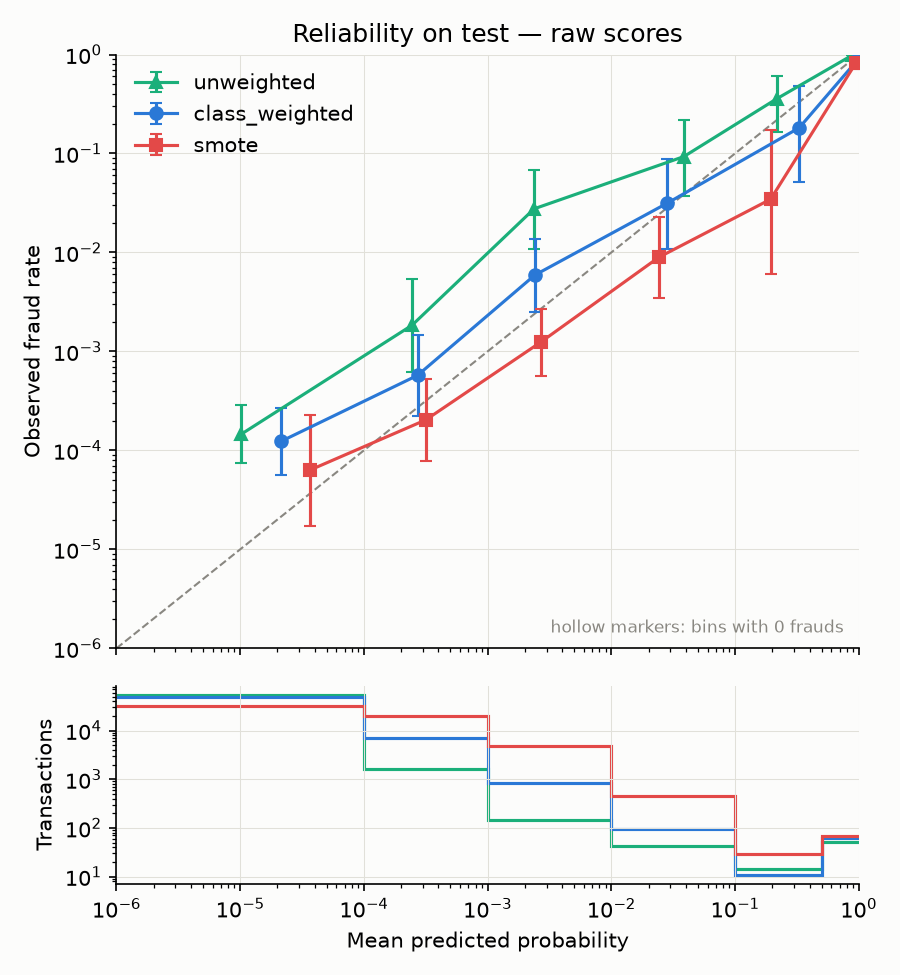

In [4]:
plot_reliability_diagram(report["raw_tables"], REPORTS_DIR / "reliability_raw.png", title="Reliability on test — raw scores")
display(Image(REPORTS_DIR / "reliability_raw.png"))

In [5]:
# The numbers behind it, per model. Note how few frauds sit in each bin.
pd.concat({name: t[["bin_lower", "bin_upper", "n", "frauds", "mean_predicted", "observed_rate"]] for name, t in report["raw_tables"].items()})

bin_lower  bin_upper      n  frauds  mean_predicted  \
unweighted     0          0     0.0001  54863       8        1.02e-05   
               1     0.0001      0.001   1630       3       0.0002452   
               2      0.001       0.01    145       4        0.002375   
               3       0.01        0.1     43       4         0.03857   
               4        0.1        0.5     14       5          0.2175   
               5        0.5          1     51      50          0.8811   
class_weighted 0          0     0.0001  48756       6       2.128e-05   
               1     0.0001      0.001   6975       4       0.0002717   
               2      0.001       0.01    847       5        0.002407   
               3       0.01        0.1     95       3         0.02845   
               4        0.1        0.5     11       2          0.3304   
               5        0.5          1     62      54          0.9696   
smote          0          0     0.0001  31696       2       3.647e-05   
               1     0.0001      0.001  19687       4       0.0003161   
               2      0.001       0.01   4818       6        0.002699   
               3       0.01        0.1    447       4         0.02425   
               4        0.1        0.5     29       1          0.1939   
               5        0.5          1     69      57          0.9505   

                  observed_rate  
unweighted     0      0.0001458  
               1        0.00184  
               2        0.02759  
               3        0.09302  
               4         0.3571  
               5         0.9804  
class_weighted 0      0.0001231  
               1      0.0005735  
               2       0.005903  
               3        0.03158  
               4         0.1818  
               5          0.871  
smote          0       6.31e-05  
               1      0.0002032  
               2       0.001245  
               3       0.008949  
               4        0.03448  
               5         0.8261

What the diagram shows, against what was predicted before running it:

- **SMOTE sits below the diagonal**: it over-predicts fraud (O/E 0.72). As expected, resampling to 50/50 inflates scores.
- **Class-weighted is close to the diagonal on average** (O/E 1.04), which was *not* expected given a class weight of ~497. Its distortion is in the *spread*: calibration slope 0.70, i.e. scores are too extreme. Reweighting barely moves the tens of thousands of transactions the model is already sure are legitimate, so the overall level is hardly affected; the inflation shows up only where the model is uncertain.
- **Unweighted sits *above* the diagonal**: it under-predicts (O/E 1.45, slope 0.86). The hypothesis was that it would come out calibrated because log loss is a proper scoring rule. That only holds at the optimum; 300 boosting rounds with no early stopping overfit the training frauds, pushing scores towards 0 and 1.

## 3. Calibration metrics on test

| Metric | Reads as |
|---|---|
| Brier | mean squared error of the probability; tiny at a 0.1% base rate, so read the skill score |
| Brier skill | 1 − Brier / Brier(always predict the base rate): 0 = no better than the base rate |
| Log loss | mean negative log-likelihood; punishes confident mistakes hardest |
| O/E | observed / expected frauds: 1 = right on average, < 1 over-predicts |
| Slope / intercept | logistic regression of y on logit(p): ideal 1 / 0; slope < 1 = overconfident |
| ECE | n-weighted mean gap per bin; secondary, because it depends on the bin edges |

In [6]:
metrics[["model", "calibration", "pr_auc", "brier_skill", "log_loss", "o_to_e", "slope", "intercept", "ece"]]

,model,calibration,pr_auc,brier_skill,log_loss,o_to_e,slope,intercept,ece
0,unweighted,raw,0.7958,0.6792,0.003006,1.453,0.856,1.034,0.0004063
1,unweighted,platt,0.7958,0.6931,0.002552,1.118,0.9924,0.3265,0.0002231
2,unweighted,isotonic,0.7596,0.6905,0.003523,1.128,0.2658,-4.482,0.0002004
3,class_weighted,raw,0.7769,0.6399,0.00303,1.036,0.7049,-1.282,0.0003185
4,class_weighted,platt,0.7769,0.6666,0.002757,1.121,0.9919,0.3725,0.0002121
5,class_weighted,isotonic,0.7469,0.6704,0.002819,1.135,0.9368,0.1125,0.0001548
6,smote,raw,0.7922,0.6508,0.002929,0.7224,0.8094,-1.832,0.0005308
7,smote,platt,0.7922,0.7126,0.002575,1.065,0.9992,0.2156,0.0001582
8,smote,isotonic,0.7616,0.7083,0.003596,1.063,0.7071,-1.531,9.245e-05


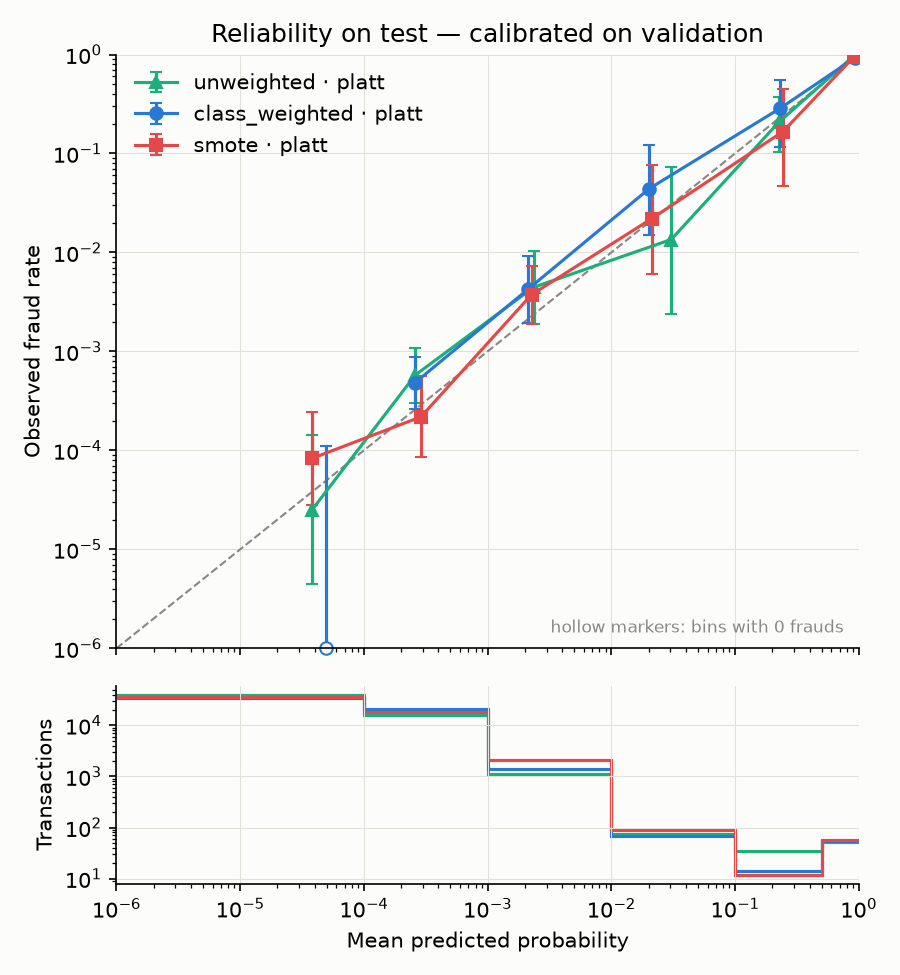

In [7]:
plot_reliability_diagram(report["calibrated_tables"], REPORTS_DIR / "reliability_calibrated.png", title="Reliability on test — calibrated on validation")
display(Image(REPORTS_DIR / "reliability_calibrated.png"))

After Platt scaling (fitted on validation), all three models land on the diagonal within their Wilson intervals, with calibration slope ≈ 1.0. Brier skill and log loss improve for every model, and PR-AUC is unchanged.

One error doesn't go away: **O/E is still about 1.1** for every calibrated model. That is the base-rate shift between windows. The calibrator learned validation's 0.10% fraud rate and test runs at 0.13%. Calibration can correct a model's distortion, but not a change in the world between the calibration window and the scoring window. In production that is what recalibration on a schedule (and drift monitoring on the base rate) is for.

## 4. Platt parameters vs the prior-shift prediction

If the *only* thing wrong with a model were that it was trained on the wrong fraud rate π′ instead of π, every log-odds score would be shifted by the same constant, logit(π′) − logit(π), and Platt would learn `a = 1`, `b = −shift`:

- class-weighted: b = −log(w), with w = n_neg / n_pos on the train slice
- SMOTE: b = logit(π) = log(π / (1 − π)) from training at 50/50

Since w = (1 − π) / π exactly, **both predictions are the same number**.

In [8]:
pd.DataFrame(report["platt_parameters"])

,model,a,b,b_prior_shift
0,unweighted,0.8625,0.7129,0
1,class_weighted,0.7107,-1.668,-6.208
2,smote,0.8101,-2.049,-6.208


The fitted intercepts (−1.67 and −2.05) are nowhere near the predicted −6.2, and `a` is 0.7–0.9 rather than 1. The prior-shift argument assumes the model has learned the exact probability under the training prior. Boosted trees don't reach that in the tails: 300 trees at learning rate 0.05 can only push log-odds so far, and the extreme legitimate transactions are saturated near 0 whatever the weighting. Because `a ≠ 1`, `b` alone isn't a pure shift either; the correction at a given score is `(a − 1)·score + b`.

**Takeaway:** the theory gives the direction and the right intuition (class weighting and SMOTE are equivalent prior shifts), but the size has to be estimated from data, which is what calibration does.

## 5. The threshold story

For a calibrated probability p, flagging costs (1 − p) · £5 in expectation and not flagging costs p · £100. Flag when the second is larger:

In [9]:
print(f"t* = C_FP / (C_FP + C_FN) = {COST_FALSE_POSITIVE:g} / ({COST_FALSE_POSITIVE:g} + {COST_FALSE_NEGATIVE:g}) = {analytic_threshold():.4f}")

thresholds = pd.DataFrame(report["thresholds"])
pivot = thresholds.pivot_table(index=["model", "calibration"], columns="rule", values=["threshold", "test_cost"], sort=False)
pivot["optimism (validation − oracle)"] = pivot[("test_cost", "validation")] - pivot[("test_cost", "oracle_test")]
pivot

t* = C_FP / (C_FP + C_FN) = 5 / (5 + 100) = 0.0476


threshold                       test_cost  \
rule                       validation analytic oracle_test validation   
model          calibration                                              
unweighted     raw               0.02  0.04762        0.02       1710   
               platt          0.08369  0.04762     0.07492       1750   
               isotonic      0.005567  0.04762     0.05182       1750   
class_weighted raw               0.02  0.04762        0.03       1915   
               platt          0.01276  0.04762     0.01845       1890   
               isotonic      0.007477  0.04762    0.007477       1890   
smote          raw               0.19  0.04762        0.18       1810   
               platt           0.0365  0.04762     0.03518       1710   
               isotonic       0.01714  0.04762      0.1006       1810   

                                                optimism (validation − oracle)  
rule                       analytic oracle_test                                 
model          calibration                                                      
unweighted     raw             1805        1710                              0  
               platt           1725        1660                             90  
               isotonic        1750        1745                              5  
class_weighted raw             1965        1850                             65  
               platt           1875        1795                             95  
               isotonic        1890        1890                              0  
smote          raw             2035        1710                            100  
               platt           1790        1710                              0  
               isotonic        1810        1780                             30

Never flagging anything costs £7,400 on test (74 missed frauds × £100); every policy here cuts that by roughly three-quarters.

**1. Raw thresholds are unstable.** In the original Phase 3 (models trained on 80% of the data, threshold searched on test) the cost-minimising raw thresholds were **0.29** (class-weighted) and **0.88** (SMOTE). The same recipes trained on 60% give **0.02** and **0.19** when searched on validation. A threshold on an uncalibrated score is a property of one particular training run, not of the business problem.

**2. Calibrated thresholds don't need searching.** After Platt, the analytic 0.048 gives test costs within £15–£80 of the validation-searched threshold, less than one missed fraud. It comes from the costs alone, so it needs no search over a validation set with 57 frauds, and it stays valid if the model is retrained (as long as it is recalibrated).

**3. The old approach was optimistic, but only by a little here.** The oracle column searches the threshold on test itself, which is what Phase 3 did. Its advantage over the honest validation-searched threshold is £0–£100, at most one fraud. Small in this case, but it is an advantage that can't exist in production, where test labels aren't available when the threshold is chosen.

**4. None of these cost gaps are statistically meaningful.** The shadow-mode A/B test (`python -m src.models.ab_test`, paired bootstrap) finds the best calibrated policy about 10% cheaper than raw class-weighting, with a 95% CI that spans zero. The two policies disagree on only 67 of 56,746 test transactions, three of them frauds.

## 6. Platt vs isotonic with 57 validation frauds

Isotonic regression fits any non-decreasing step function, so it can correct shapes Platt can't. It pays for that flexibility in data: each step is an average over a run of transactions, and with 57 frauds most steps rest on one or two.

In [10]:
cv = pd.DataFrame(report["cv_log_loss_on_validation"]).T.add_prefix("cv_log_loss_val_")
test_ll = metrics.pivot(index="model", columns="calibration", values="log_loss")[["platt", "isotonic"]].add_prefix("log_loss_test_")
test_pr = metrics.pivot(index="model", columns="calibration", values="pr_auc")[["raw", "isotonic"]].add_prefix("pr_auc_test_")
steps = pd.Series(
    {name: len(np.unique(cals["isotonic"].isotonic.y_thresholds_)) for name, cals in report["calibrators"].items()},
    name="isotonic_distinct_levels",
)
pd.concat([cv, test_ll, test_pr, steps], axis=1)

,cv_log_loss_val_platt,cv_log_loss_val_isotonic,log_loss_test_platt,log_loss_test_isotonic,pr_auc_test_raw,pr_auc_test_isotonic,isotonic_distinct_levels
unweighted,0.002122,0.003128,0.002552,0.003523,0.7958,0.7596,10
class_weighted,0.002174,0.003199,0.002757,0.002819,0.7769,0.7469,10
smote,0.002363,0.00283,0.002575,0.003596,0.7922,0.7616,12


- **Platt wins on log loss**, both in 5-fold cross-validation inside validation (which is how the method was chosen, without looking at test) and on test. For class-weighted the two are close; for the other two isotonic is clearly worse.
- **Isotonic costs about 0.03 PR-AUC.** Its output has only a handful of distinct levels, so many transactions with different raw scores get tied, and ties lose ranking information. Platt is strictly increasing, so it loses none.
- On IEEE-CIS (~3.5% fraud), a validation slice would hold thousands of frauds and isotonic would become a reasonable choice. With rare events, a two-parameter calibrator is the safer default.

## 7. Limitations

- **Small fraud counts.** 57 validation and 74 test frauds. Every metric here has wide uncertainty; the Wilson intervals on the reliability diagrams show how wide.
- **A two-day dataset.** "Time-ordered" means hours, not months: train covers hours 0–33, validation 33–40, test 40–48. This tests generalisation to the next few hours, not to next quarter, and says nothing about seasonality.
- **One calibration window.** The calibrator is fitted on a single 7-hour validation window whose fraud rate (0.10%) differs from test's (0.13%), which leaves O/E ≈ 1.1 after calibration. A production system would recalibrate on a rolling window and monitor the base rate.
- **No refit after selection.** Models are trained on the 60% train slice only and not refitted on train + validation, so that the calibrator stays matched to the exact model it corrects. The cost is ~57k fewer, more recent training rows.
- **`Time` is a model feature.** Under a time-ordered split, test values of `Time` lie outside the training range, so trees can only learn "when", not "what". Removing it changes the API schema, so it's noted as a next step rather than changed here.